# EDA région Auvergne-Rhône-Alpes : croiser les stations Citiz avec le territoire

**Question** : qu'est-ce qui distingue les communes où Citiz a une station de celles où il n'y en a pas, selon le type de territoire ? Et l'idée de départ tient-elle : les stations sont-elles en périphérie des grandes villes, et les petites communes sont-elles peu desservies, selon les flux domicile-travail ?

**Données** (toutes dans `eda-citiz/donnees/`) : stations Citiz (`sorties/stations.csv`), communes (geo.api.gouv.fr), aires d'attraction des villes 2020, flux domicile-travail 2023, dossier complet du recensement 2023 (motorisation), arrêts de transport (agrégat GTFS), bornes de recharge (IRVE), population et revenus au carreau de 200 m (Filosofi 2021).

**Limite à garder en tête** : on compte des stations, pas des usages. Une station présente ne dit pas qu'elle marche ; l'usage viendra du relevé de disponibilité Citiz.

**Ordre** : lancer les cellules dans l'ordre, de la 0 à la 12. Les cellules 2 à 10 construisent les tables, les 11 et 12 lisent les résultats.

## Cellule 0 : imports

Les bibliothèques utilisées dans tout le notebook. Si une importation échoue avec `ModuleNotFoundError`, installer le paquet dans le terminal du `.venv` avec `python -m pip install <paquet>`.

In [19]:
from pathlib import Path
import io, re, time, zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import pyarrow.parquet as pq
import requests
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from shapely.geometry import box
from IPython.display import display

## Cellule 1 : paramètres et outils

**Paramètres et petites fonctions utilitaires** : chemins, liste des 12 départements d'Auvergne-Rhône-Alpes, projection Lambert 93 (en mètres, nécessaire pour mesurer des distances), lecture des fichiers INSEE, calcul de distances et de comptages autour d'un point. Rien n'est calculé ici ; la dernière ligne affiche les fichiers présents dans `donnees/` pour vérifier que les téléchargements sont au bon endroit.

In [20]:
EDA = Path(r"C:\Users\bilel\Desktop\epitech\T-HAK-700-MAR-7-1-hack-7\eda-citiz")   # dossier du notebook
DONNEES = EDA / "donnees"                      # fichiers INSEE déjà téléchargés + ceux que les cellules ajoutent
DONNEES.mkdir(parents=True, exist_ok=True)
DEPS_ARA = ["01", "03", "07", "15", "26", "38", "42", "43", "63", "69", "73", "74"]
BBOX_ARA = (2.06, 44.11, 7.19, 46.81)          # lon_min, lat_min, lon_max, lat_max
L93 = "EPSG:2154"                              # Lambert 93, en mètres
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
S = requests.Session()
S.headers["User-Agent"] = "hackathon-mobilite-citiz/0.1"

print(DONNEES.resolve())
print(sorted(p.name for p in DONNEES.iterdir()))

def num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False), errors="coerce")

def telecharger(url, nom):
    """Télécharge une seule fois dans DONNEES, puis réutilise le fichier."""
    chemin = DONNEES / nom
    if not chemin.exists():
        with S.get(url, stream=True, timeout=600) as r:
            r.raise_for_status()
            with open(chemin, "wb") as f:
                for bloc in r.iter_content(1 << 20):
                    f.write(bloc)
    print(nom, ":", round(chemin.stat().st_size / 1e6, 1), "Mo")
    return chemin

def ressource_datagouv(slug, format_="csv"):
    meta = S.get(f"https://www.data.gouv.fr/api/1/datasets/{slug}/", timeout=30).json()
    res = [r for r in meta["resources"] if (r.get("format") or "").lower() == format_]
    for r in res[:5]:
        print(" -", r["title"], "|", r.get("filesize"), "|", r["url"])
    return res[0]["url"]

def fichier(motif):
    trouves = sorted(DONNEES.glob(motif))
    if not trouves:
        raise FileNotFoundError(f"Aucun fichier {motif} dans {DONNEES}")
    print("Lu :", trouves[-1].name)
    return trouves[-1]

def lire_insee(chemin, cles=("CODGEO",)):
    """Lit un fichier INSEE (csv, xlsx, ou zip qui en contient un) en cherchant la ligne d'en-tête."""
    chemin = Path(chemin)
    if chemin.suffix.lower() == ".zip":
        z = zipfile.ZipFile(chemin)
        noms = [n for n in z.namelist() if n.lower().endswith((".csv", ".xlsx"))]
        nom = max(noms, key=lambda n: z.getinfo(n).file_size)   # le plus gros = les données
        source, ext = io.BytesIO(z.read(nom)), Path(nom).suffix.lower()
    else:
        source, ext = chemin, chemin.suffix.lower()
    if ext == ".csv":
        return pd.read_csv(source, sep=";", dtype=str)
    xls = pd.ExcelFile(source, engine="calamine")   # openpyxl plante sur certains xlsx INSEE (styles invalides)
    for feuille in xls.sheet_names:
        tete = xls.parse(feuille, header=None, nrows=30).astype(str)
        for cle in cles:
            lignes = tete.index[tete.eq(cle).any(axis=1)]
            if len(lignes):
                df = xls.parse(feuille, skiprows=lignes[0], dtype=str)
                return df.rename(columns={cle: "CODGEO"})
    raise ValueError(f"{cles} introuvable dans {chemin.name}, feuilles : {xls.sheet_names}")

def commune_parente(code):
    """Les arrondissements de Lyon, Paris et Marseille sont ramenés à leur commune."""
    code = str(code)
    if "69381" <= code <= "69389": return "69123"
    if "75101" <= code <= "75120": return "75056"
    if "13201" <= code <= "13216": return "13055"
    return code

def sans_arrondissements(df, col="CODGEO"):
    parent = df[col].map(commune_parente)
    doublon = (parent != df[col]) & parent.isin(df[col])   # la commune entière est déjà là
    df = df[~doublon].copy()
    df[col] = df[col].map(commune_parente)
    return df

def compter_autour(xy_de, xy_vers, rayon, poids=None):
    """Nombre (ou somme des poids) de points à moins de `rayon` mètres de chaque point de départ."""
    voisins = cKDTree(xy_vers).query_ball_point(xy_de, rayon)
    if poids is None:
        return np.array([len(v) for v in voisins])
    poids = np.asarray(poids, dtype=float)
    return np.array([poids[v].sum() for v in voisins])

def plus_proche(xy_de, xy_vers):
    return cKDTree(xy_vers).query(xy_de)[0]

C:\Users\bilel\Desktop\epitech\T-HAK-700-MAR-7-1-hack-7\eda-citiz\donnees
['AAV2020_au_01-01-2026.zip', 'Filosofi2021_carreaux_200m_gpkg.zip', 'arrets_france.csv', 'base-flux-mobilite-domicile-lieu-travail-2023_csv.zip', 'carreaux_ara.parquet', 'citiz_alpes_loire_station_information_2026-10-19.json', 'citiz_alpes_loire_vehicle_types_2026-10-19.json', 'citiz_auto_en_velay_station_information_2026-10-19.json', 'citiz_auto_en_velay_vehicle_types_2026-10-19.json', 'citiz_lyon_station_information_2026-10-19.json', 'citiz_lyon_vehicle_types_2026-10-19.json', 'communes_01.geojson', 'communes_03.geojson', 'communes_07.geojson', 'communes_15.geojson', 'communes_26.geojson', 'communes_38.geojson', 'communes_42.geojson', 'communes_43.geojson', 'communes_63.geojson', 'communes_69.geojson', 'communes_73.geojson', 'communes_74.geojson', 'communes_ara.gpkg', 'communes_croisees.parquet', 'dossier_communes.parquet', 'dossier_complet.parquet', 'fichier_diffusion_2026.xlsx', 'filosofi', 'irve_consolide.c

## Cellule 2 : communes de la région (contours, population)

**Les communes de la région** (contours, population, surface), téléchargées une fois par département depuis geo.api.gouv.fr puis gardées dans `donnees/`. C'est l'unité d'analyse : on regarde quelles communes ont une station et lesquelles n'en ont pas. *À vérifier : environ 4 000 communes et 8 millions d'habitants.*

In [21]:
def communes_dep(dep):
    f = DONNEES / f"communes_{dep}.geojson"
    if not f.exists():
        url = (f"https://geo.api.gouv.fr/departements/{dep}/communes"
               "?fields=nom,code,population,surface,codeDepartement&format=geojson&geometry=contour")
        for essai in range(5):
            try:
                r = S.get(url, timeout=(15, 300))
                r.raise_for_status()
                f.write_bytes(r.content)
                break
            except requests.RequestException as e:
                print(dep, "essai", essai + 1, "échec :", type(e).__name__)
                time.sleep(5 * (essai + 1))
        else:
            raise RuntimeError(f"Département {dep} : l'API ne répond pas, relance la cellule plus tard")
    print(dep, "ok")
    return gpd.read_file(f)

cache = DONNEES / "communes_ara.gpkg"
if cache.exists():
    com = gpd.read_file(cache)
else:
    com = pd.concat([communes_dep(d) for d in DEPS_ARA], ignore_index=True)
    com = com.set_crs("EPSG:4326", allow_override=True).to_crs(L93)
    com.to_file(cache)
com["population"] = com["population"].fillna(0)
com["surface_km2"] = com["surface"] / 100            # l'API donne la surface en hectares
com["densite_hab_km2"] = com["population"] / com["surface_km2"]
print(len(com), "communes,", int(com["population"].sum()), "habitants")
com.head(3)

4025 communes, 8205557 habitants


,nom,code,population,surface,codeDepartement,geometry,surface_km2,densite_hab_km2
0,L'Abergement-Clémenciat,01001,860,1564.50,01,"MULTIPOLYGON (((851129.631 6563369.164, 851107...",15.6450,54.969639
1,L'Abergement-de-Varey,01002,270,919.01,01,"MULTIPOLYGON (((888109.67 6545455.936, 888094....",9.1901,29.379441
2,Ambérieu-en-Bugey,01004,15934,2454.80,01,"MULTIPOLYGON (((886593.018 6540886.024, 886567...",24.5480,649.095649


## Cellule 3 : stations Citiz, rattachées aux communes

**Les 622 stations Citiz réelles** (sans les deux fausses stations), rattachées à leur commune par position. On compte ensuite les stations par commune et on marque les communes « desservies ». *À vérifier : 622 stations ; le nombre de communes desservies doit être proche de 130.*

In [22]:
st = pd.read_csv(EDA / "sorties" / "stations.csv", dtype={"code_insee": str, "departement": str})
st = st[(st["region"] == "Auvergne-Rhône-Alpes") & (~st["ouverture_prochaine"].astype(bool))]
st = st[~st["nom"].str.contains("hors-circuit|DEMOBOX", case=False)].copy()   # les 2 fausses stations
st = gpd.GeoDataFrame(st, geometry=gpd.points_from_xy(st["lon"], st["lat"]), crs="EPSG:4326").to_crs(L93)
st = gpd.sjoin(st, com[["code", "geometry"]], how="left", predicate="within").drop(columns="index_right")
print(len(st), "stations (attendu : 622)")
print("Commune différente de la première EDA :", int((st["code"] != st["code_insee"]).sum()))
XY_ST = np.c_[st.geometry.x, st.geometry.y]

com = com.merge(st.groupby("code").size().rename("nb_stations"), left_on="code", right_index=True, how="left")
com["nb_stations"] = com["nb_stations"].fillna(0).astype(int)
com["desservie"] = com["nb_stations"] > 0
print(int(com["desservie"].sum()), "communes desservies sur", len(com))

622 stations (attendu : 622)
Commune différente de la première EDA : 3
129 communes desservies sur 4025


## Cellule 4 : type de territoire (aires d'attraction et densité)

**Type de territoire** : chaque commune est classée selon son aire d'attraction des villes (INSEE) : taille de l'aire (grande, moyenne, petite, hors aire) et position (pôle ou couronne). C'est la grille qui permet de tester l'idée « périphérie des grandes villes ». Le tableau final compte, par type de territoire, les communes, les habitants, les communes desservies et les stations.

In [23]:
aav = lire_insee(fichier("AAV2020*"))
dens = lire_insee(fichier("fichier_diffusion*"), cles=("CODGEO", "Code commune", "COM"))
print("AAV :", aav.columns.tolist())
print("Densité :", dens.columns.tolist())

col_dens = [c for c in dens.columns if "DENS" in c.upper() and "LIB" not in c.upper()][0]
col_libdens = [c for c in dens.columns if "LIBDENS" in c.upper() or "LIBELLÉ" in c.upper()]
dens = dens[["CODGEO", col_dens] + col_libdens[:1]].rename(columns={col_dens: "dens"})
if col_libdens:
    dens = dens.rename(columns={col_libdens[0]: "lib_dens"})
print("Colonne densité retenue :", col_dens)

com = com.merge(aav[["CODGEO", "AAV2020", "LIBAAV2020", "CATEAAV2020"]], left_on="code", right_on="CODGEO", how="left").drop(columns="CODGEO")
com = com.merge(dens, left_on="code", right_on="CODGEO", how="left").drop(columns="CODGEO")

# Position dans l'aire : 11 commune-centre, 12 autre commune du pôle principal, 13 pôle secondaire, 20 couronne, 30 hors attraction
POSITION = {"11": "pôle", "12": "pôle", "13": "pôle secondaire", "20": "couronne", "30": "hors aire"}
com["position"] = com["CATEAAV2020"].astype(str).str[:2].map(POSITION)
pop_aire = com[com["position"] != "hors aire"].groupby("AAV2020")["population"].sum()   # partie située dans la région
com["pop_aire"] = com["AAV2020"].map(pop_aire)
com["taille_aire"] = pd.cut(com["pop_aire"], [0, 100_000, 400_000, np.inf],
                            labels=["3 petite aire (< 100 000)", "2 aire moyenne (100 à 400 000)", "1 grande aire (≥ 400 000)"]).astype(str)
com.loc[com["position"] == "hors aire", "taille_aire"] = "4 hors aire"
com["territoire"] = com["taille_aire"].str.replace(r" \(.*\)", "", regex=True) + " · " + com["position"]

print("Communes sans aire trouvée :", int(com["position"].isna().sum()))
display(com.groupby("territoire").agg(communes=("code", "size"), habitants=("population", "sum"),
                                      desservies=("desservie", "sum"), stations=("nb_stations", "sum")))
display(pop_aire.sort_values(ascending=False).head(10).rename(lambda a: com.loc[com["AAV2020"] == a, "LIBAAV2020"].iloc[0]))

Lu : AAV2020_au_01-01-2026.zip
Lu : fichier_diffusion_2026.xlsx
AAV : ['CODGEO', 'LIBGEO', 'AAV2020', 'LIBAAV2020', 'CATEAAV2020', 'DEP', 'REG']
Densité : ['CODGEO', 'LIBGEO', 'DENS', 'LIBDENS', 'PMUN23', 'P1', 'P2', 'P3', 'DENS_AAV', 'LIBDENS_AAV', 'DENS7', 'LIBDENS7']
Colonne densité retenue : DENS
Communes sans aire trouvée : 0


,communes,habitants,desservies,stations
territoire,,,,
1 grande aire · couronne,1011,2414862,37,68
1 grande aire · pôle,61,2126818,38,406
2 aire moyenne · couronne,444,709630,18,30
2 aire moyenne · pôle,22,503432,14,84
3 petite aire · couronne,1174,970896,7,7
3 petite aire · pôle,116,820145,9,19
4 hors aire · hors aire,1197,659774,6,8


AAV2020
Lyon                                     2339329
Grenoble                                  727380
Clermont-Ferrand                          510668
Saint-Étienne                             503351
Genève - Annemasse (partie française)     460952
Annecy                                    303877
Chambéry                                  266137
Valence                                   258609
Bourg-en-Bresse                           144666
Roanne                                    138290
Name: population, dtype: int32

## Cellule 5 : flux domicile-travail

**Flux domicile-travail** (recensement 2023) : pour chaque commune, part des actifs qui travaillent hors de leur commune, au pôle de leur aire, ou dans un grand pôle. Les arrondissements de Lyon, Paris et Marseille sont regroupés. *Contrôle : les actifs doivent représenter environ 40 à 45 % des habitants.*

In [24]:
flux = lire_insee(fichier("base-flux-mobilite-domicile-lieu-travail*"))
print(flux.columns.tolist(), len(flux), "lignes")
col_n = next(c for c in flux.columns if c.upper().startswith("NBFLUX"))
flux["n"] = num(flux[col_n])
flux["orig"] = flux["CODGEO"].map(commune_parente)
flux["dest"] = flux["DCLT"].map(commune_parente)
flux = flux.groupby(["orig", "dest"], as_index=False)["n"].sum()

info = com.set_index("code")[["AAV2020", "position", "taille_aire"]]
flux = flux.join(info.add_suffix("_o"), on="orig").join(info.add_suffix("_d"), on="dest")
ailleurs = flux["orig"] != flux["dest"]
vers_pole_aire = ailleurs & (flux["position_d"] == "pôle") & (flux["AAV2020_o"] == flux["AAV2020_d"])
vers_grand_pole = ailleurs & (flux["position_d"] == "pôle") & flux["taille_aire_d"].astype(str).str.startswith("1")

f = pd.DataFrame({
    "actifs": flux.groupby("orig")["n"].sum(),
    "emplois": flux.groupby("dest")["n"].sum(),
    "sur_place": flux[~ailleurs].groupby("orig")["n"].sum(),
    "vers_pole_aire": flux[vers_pole_aire].groupby("orig")["n"].sum(),
    "vers_grand_pole": flux[vers_grand_pole].groupby("orig")["n"].sum(),
}).fillna(0)
f["part_sortants"] = 1 - f["sur_place"] / f["actifs"]
f["part_vers_pole_aire"] = f["vers_pole_aire"] / f["actifs"]
f["part_vers_grand_pole"] = f["vers_grand_pole"] / f["actifs"]
f["emplois_par_actif"] = f["emplois"] / f["actifs"]
com = com.merge(f, left_on="code", right_index=True, how="left")

# Contrôle : les actifs occupés font environ 40 à 45 % de la population. Beaucoup moins = petits flux coupés par l'INSEE.
print("Actifs / habitants dans la région :", round(com["actifs"].sum() / com["population"].sum(), 3))
print("Communes sans aucun flux :", int(com["actifs"].isna().sum()))
display(com.groupby("territoire")[["part_sortants", "part_vers_pole_aire", "part_vers_grand_pole", "emplois_par_actif"]].median().round(2))

Lu : base-flux-mobilite-domicile-lieu-travail-2023_csv.zip
['CODGEO', 'LIBGEO', 'DCLT', 'L_DCLT', 'NBFLUX_C23_ACTOCC15P'] 1003647 lignes
Actifs / habitants dans la région : 0.438
Communes sans aucun flux : 11


,part_sortants,part_vers_pole_aire,part_vers_grand_pole,emplois_par_actif
territoire,,,,
1 grande aire · couronne,0.83,0.25,0.26,0.38
1 grande aire · pôle,0.77,0.56,0.57,0.99
2 aire moyenne · couronne,0.81,0.30,0.02,0.37
2 aire moyenne · pôle,0.75,0.46,0.03,1.06
3 petite aire · couronne,0.80,0.25,0.01,0.41
3 petite aire · pôle,0.62,0.03,0.02,1.26
4 hors aire · hors aire,0.69,0.00,0.01,0.54


## Cellule 5b : extraire les communes du dossier complet (une seule fois)

**À faire une seule fois.** Le « dossier complet » de l'INSEE est un très gros fichier au format long. On en extrait les lignes des communes pour quelques tableaux (voitures des ménages, résidences principales, mode de transport, revenus) et on enregistre un petit fichier, `dossier_communes.parquet`, que la cellule suivante lit en une seconde.

Le parquet est au format long (une ligne par commune, tableau, mesure et année). On garde les communes de quelques tableaux et on enregistre un petit fichier.

In [25]:
TABLEAUX = ["LOG_T12", "LOG_T10", "LOG_T5", "FAM_T1", "ACT_G2", "REV_T1"]
cols = ["GEO", "GEO_OBJECT", "TIME_PERIOD", "ID_TAB", "TAB_MEASURE", "TAB_MEASURE_LABEL", "OBS_VALUE"]
pf = pq.ParquetFile(DONNEES / "dossier_complet.parquet")
morceaux = []
for lot in pf.iter_batches(batch_size=500_000, columns=cols):
    d = lot.to_pandas()
    morceaux.append(d[d["ID_TAB"].isin(TABLEAUX) & (d["GEO_OBJECT"] == "COM")])
dossier = pd.concat(morceaux, ignore_index=True)
dossier.to_parquet(DONNEES / "dossier_communes.parquet")
print(len(dossier), "lignes")

4845082 lignes


## Cellule 6 : motorisation des ménages

**Motorisation des ménages** (recensement 2023) : part des ménages sans voiture et part des ménages avec deux voitures ou plus, par commune. C'est la variable clé de l'autopartage : plus la part sans voiture est élevée, plus un partage de voiture a de sens.

In [26]:
dossier = pd.read_parquet(DONNEES / "dossier_communes.parquet")
d23 = dossier[dossier["TIME_PERIOD"].astype(str) == "2023"]
voit = (d23[d23["ID_TAB"] == "LOG_T12"]
        .pivot_table(index="GEO", columns="TAB_MEASURE", values="OBS_VALUE", aggfunc="sum"))
menages = (d23[(d23["ID_TAB"] == "LOG_T5") & (d23["TAB_MEASURE"] == "DWELLINGS_OCS_DW_MAIN")]
           .groupby("GEO")["OBS_VALUE"].sum())
moto = pd.DataFrame({"menages": menages,
                     "avec_voiture": voit["DWELLINGS_OCS_DW_MAIN_CARS_C_GE1"],
                     "deux_voitures": voit["DWELLINGS_OCS_DW_MAIN_CARS_C_GE2"]})
moto["part_sans_voiture"] = (1 - moto["avec_voiture"] / moto["menages"]).clip(0, 1)
moto["part_2_voitures"] = moto["deux_voitures"] / moto["menages"]
print(len(moto), "communes ; ménages en France :", int(moto["menages"].sum()))
com = com.merge(moto[["menages", "part_sans_voiture", "part_2_voitures"]], left_on="code", right_index=True, how="left")
print("Communes sans motorisation :", int(com["part_sans_voiture"].isna().sum()))
display(com.groupby("territoire")[["part_sans_voiture", "part_2_voitures"]].median().round(3))

34858 communes ; ménages en France : 31220146
Communes sans motorisation : 0


,part_sans_voiture,part_2_voitures
territoire,,
1 grande aire · couronne,0.038,0.593
1 grande aire · pôle,0.158,0.308
2 aire moyenne · couronne,0.037,0.579
2 aire moyenne · pôle,0.120,0.333
3 petite aire · couronne,0.048,0.530
3 petite aire · pôle,0.141,0.356
4 hors aire · hors aire,0.061,0.471


## Cellule 7 : arrêts de transport en commun

**Arrêts de transport en commun** (agrégat national GTFS), filtrés sur la région et dédoublonnés. Pour chaque station : nombre d'arrêts à moins de 300 m et distance à l'arrêt le plus proche ; pour chaque commune : arrêts pour 1 000 habitants. On ne connaît pas encore la fréquence de passage, seulement la présence des arrêts.

In [27]:
url = ressource_datagouv("arrets-de-transport-en-france")
arrets = pd.read_csv(telecharger(url, "arrets_france.csv"), low_memory=False)
print(arrets.columns.tolist())
x0, y0, x1, y1 = BBOX_ARA
arrets = arrets[arrets["stop_lon"].between(x0, x1) & arrets["stop_lat"].between(y0, y1)]
if "location_type" in arrets:
    arrets = arrets[arrets["location_type"].fillna(0).astype(str).isin(["0", "0.0"])]   # quais, pas les zones d'arrêt
# Dédoublonnage : même nom à moins d'environ 10 m (plusieurs réseaux publient le même arrêt)
arrets["cle"] = (arrets["stop_name"].astype(str).str.lower().str.strip() + "|"
                 + arrets["stop_lat"].round(4).astype(str) + "|" + arrets["stop_lon"].round(4).astype(str))
avant = len(arrets)
arrets = arrets.drop_duplicates("cle")
arrets = gpd.GeoDataFrame(arrets, geometry=gpd.points_from_xy(arrets["stop_lon"], arrets["stop_lat"]), crs="EPSG:4326").to_crs(L93)
arrets = gpd.sjoin(arrets, com[["code", "geometry"]], how="inner", predicate="within")
print(avant, "arrêts dans le cadre,", len(arrets), "après dédoublonnage et dans la région")
XY_ARRETS = np.c_[arrets.geometry.x, arrets.geometry.y]

st["arrets_300m"] = compter_autour(XY_ST, XY_ARRETS, 300)
st["dist_arret_m"] = plus_proche(XY_ST, XY_ARRETS)
com = com.merge(arrets.groupby("code").size().rename("nb_arrets"), left_on="code", right_index=True, how="left")
com["nb_arrets"] = com["nb_arrets"].fillna(0)
com["arrets_pour_1000_hab"] = com["nb_arrets"] / com["population"].clip(lower=1) * 1000
print(st["dist_arret_m"].describe().round(0))

 - gtfs_stops_france_export_2026-01-13.csv | 436967705 | https://static.data.gouv.fr/resources/arrets-de-transport-en-france/20260113-104155/gtfs-stops-france-export-2026-01-13.csv
arrets_france.csv : 437.0 Mo
['dataset_custom_title', 'dataset_organisation', 'dataset_id', 'dataset_datagouv_id', 'resource_id', 'resource_datagouv_id', 'resource_title', 'di_id', 'stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'location_type', 'agency_id', 'agency_name']
67575 arrêts dans le cadre, 35150 après dédoublonnage et dans la région
count     622.0
mean      367.0
std       575.0
min         4.0
25%        60.0
50%       132.0
75%       399.0
max      4010.0
Name: dist_arret_m, dtype: float64


## Cellule 8 : bornes de recharge publiques

**Bornes de recharge publiques** (fichier consolidé IRVE) : nombre de points de charge à moins de 300 m de chaque station et distance à la plus proche. Cela prépare la question « la voiture peut-elle être électrique ? ». La puissance est en kW (médiane autour de 22).

In [28]:
url = ressource_datagouv("fichier-consolide-des-bornes-de-recharge-pour-vehicules-electriques")
irve = pd.read_csv(telecharger(url, "irve_consolide.csv"), low_memory=False)
print(irve.columns.tolist()[:40])
col_lon = next(c for c in irve.columns if "longitude" in c.lower())
col_lat = next(c for c in irve.columns if "latitude" in c.lower())
col_kw = next(c for c in irve.columns if "puissance_nominale" in c.lower())
irve["lon"], irve["lat"], irve["kw"] = num(irve[col_lon]), num(irve[col_lat]), num(irve[col_kw])
x0, y0, x1, y1 = BBOX_ARA
irve = irve[irve["lon"].between(x0, x1) & irve["lat"].between(y0, y1)]
irve = gpd.GeoDataFrame(irve, geometry=gpd.points_from_xy(irve["lon"], irve["lat"]), crs="EPSG:4326").to_crs(L93)
irve = gpd.sjoin(irve, com[["code", "geometry"]], how="inner", predicate="within")
print(len(irve), "points de charge dans la région")
print("Puissance (kW) :", irve["kw"].describe().round(1).to_dict())   # certains fichiers donnent des W : à vérifier
XY_IRVE = np.c_[irve.geometry.x, irve.geometry.y]

st["irve_300m"] = compter_autour(XY_ST, XY_IRVE, 300)
st["dist_irve_m"] = plus_proche(XY_ST, XY_IRVE)
com = com.merge(irve.groupby("code").size().rename("nb_points_charge"), left_on="code", right_index=True, how="left")
com["nb_points_charge"] = com["nb_points_charge"].fillna(0)
print("Stations avec un point de charge à moins de 300 m :", int((st["irve_300m"] > 0).sum()), "sur", len(st))

 - Consolidation de la dernière version à date du schéma (v2.3.1) - 20261019 | 108523272 | https://static.data.gouv.fr/resources/base-nationale-des-irve-data-gouv-infrastructures-de-recharge-pour-vehicules-electriques-donnees-statiques/20261019-032122/consolidation-etalab-schema-irve-statique-v-2.3.1-20261019.csv
 - Consolidation de la v2.3.1 du schéma - 20261019 | 108523272 | https://static.data.gouv.fr/resources/base-nationale-des-irve-data-gouv-infrastructures-de-recharge-pour-vehicules-electriques-donnees-statiques/20261019-032104/consolidation-etalab-schema-irve-statique-v-2.3.1-20261019.csv
 - Documentation sur la consolidation - 20261019 | 1435411 | https://static.data.gouv.fr/resources/base-nationale-des-irve-data-gouv-infrastructures-de-recharge-pour-vehicules-electriques-donnees-statiques/20261019-032301/ref-table-etalab-schema-irve-statique.csv
irve_consolide.csv : 108.5 Mo
['nom_amenageur', 'siren_amenageur', 'contact_amenageur', 'nom_operateur', 'contact_operateur', 'telep

## Cellule 9 : population et revenus au carreau de 200 m

**Population et revenus au carreau de 200 m** (Filosofi 2021, France métropolitaine) : habitants, ménages, niveau de vie et part de ménages pauvres dans un rayon de 500 m autour de chaque station. On ne lit que le cadre de la région. *Contrôle : le total d'habitants doit être proche de celui de la cellule 2.*

In [29]:
gpkg = DONNEES / "filosofi" / "carreaux_200m_met.gpkg"
couches = pyogrio.list_layers(gpkg)
print("Fichier :", gpkg.name, "| couches :", couches.tolist())
couche = couches[0][0]
print("Couche lue :", couche)
car = gpd.read_file(gpkg, layer=couche, bbox=cadre)     # ne lit que le cadre de la région
car.columns = [c.lower() if c != "geometry" else c for c in car.columns]
print(len(car), "carreaux lus ;", car.columns.tolist())
car = car.to_crs(L93)
car["geometry"] = car.geometry.centroid
car = gpd.sjoin(car, com[["code", "geometry"]], how="inner", predicate="within").drop(columns="index_right")
XY_CAR = np.c_[car.geometry.x, car.geometry.y]
print(len(car), "carreaux dans la région,", int(car["ind"].sum()), "habitants (à comparer à la cellule 2)")

st["pop_500m"] = compter_autour(XY_ST, XY_CAR, 500, car["ind"])
st["men_500m"] = compter_autour(XY_ST, XY_CAR, 500, car["men"])
st["niveau_vie_500m"] = compter_autour(XY_ST, XY_CAR, 500, car["ind_snv"]) / st["pop_500m"].clip(lower=1)
st["part_pauvres_500m"] = compter_autour(XY_ST, XY_CAR, 500, car["men_pauv"]) / st["men_500m"].clip(lower=1)

rev = car.groupby("code")[["ind", "ind_snv"]].sum()
com = com.merge((rev["ind_snv"] / rev["ind"]).rename("niveau_vie_moyen"), left_on="code", right_index=True, how="left")
car["dist_station_m"] = plus_proche(XY_CAR, XY_ST)        # servira à la partie 2
print(st[["pop_500m", "niveau_vie_500m", "part_pauvres_500m"]].describe().round(2))

Fichier : carreaux_200m_met.gpkg | couches : [['carreaux_200m_met', 'Polygon']]
Couche lue : carreaux_200m_met
434083 carreaux lus ; ['idcar_200m', 'idcar_1km', 'idcar_nat', 'i_est_200', 'i_est_1km', 'lcog_geo', 'ind', 'men', 'men_pauv', 'men_1ind', 'men_5ind', 'men_prop', 'men_fmp', 'ind_snv', 'men_surf', 'men_coll', 'men_mais', 'log_av45', 'log_45_70', 'log_70_90', 'log_ap90', 'log_inc', 'log_soc', 'ind_0_3', 'ind_4_5', 'ind_6_10', 'ind_11_17', 'ind_18_24', 'ind_25_39', 'ind_40_54', 'ind_55_64', 'ind_65_79', 'ind_80p', 'ind_inc', 'geometry']
311660 carreaux dans la région, 7699493 habitants (à comparer à la cellule 2)
       pop_500m  niveau_vie_500m  part_pauvres_500m
count    622.00           622.00             622.00
mean    6609.67         26519.75               0.16
std     4576.25          4398.95               0.06
min        0.00             0.00               0.00
25%     2934.62         23456.13               0.12
50%     5805.00         26141.87               0.16
75%     

## Cellule 10 : assembler et enregistrer

**Assemblage et sauvegarde** : une table par station, une par commune et une par carreau, enregistrées en Parquet dans `donnees/` pour ne pas tout recalculer. Le tableau final donne les valeurs médianes par type de territoire.

In [30]:
VARS_COM = ["code", "territoire", "taille_aire", "position", "LIBAAV2020", "dens", "densite_hab_km2", "population",
            "part_sortants", "part_vers_pole_aire", "part_vers_grand_pole", "emplois_par_actif",
            "part_sans_voiture", "part_2_voitures", "arrets_pour_1000_hab", "niveau_vie_moyen"]
st_x = st.drop(columns=["population"], errors="ignore").merge(com[VARS_COM], on="code", how="left")
st_x.drop(columns="geometry").to_parquet(DONNEES / "stations_croisees.parquet")
com.drop(columns="geometry").to_parquet(DONNEES / "communes_croisees.parquet")
car.drop(columns="geometry").assign(x=XY_CAR[:, 0], y=XY_CAR[:, 1]).to_parquet(DONNEES / "carreaux_ara.parquet")

print("Valeurs manquantes par variable (stations) :")
print(st_x[["territoire", "part_vers_grand_pole", "part_sans_voiture", "pop_500m", "dist_arret_m", "dist_irve_m"]].isna().sum())
display(st_x.groupby("territoire")[["pop_500m", "niveau_vie_500m", "arrets_300m", "irve_300m", "part_sans_voiture"]].median().round(2))

Valeurs manquantes par variable (stations) :
territoire              0
part_vers_grand_pole    0
part_sans_voiture       0
pop_500m                0
dist_arret_m            0
dist_irve_m             0
dtype: int64


,pop_500m,niveau_vie_500m,arrets_300m,irve_300m,part_sans_voiture
territoire,,,,,
1 grande aire · couronne,2446.25,26709.23,3.0,4.0,0.10
1 grande aire · pôle,7948.75,26788.04,2.0,4.0,0.40
2 aire moyenne · couronne,1576.50,26313.16,6.0,2.0,0.10
2 aire moyenne · pôle,5221.25,25538.82,7.0,2.0,0.24
3 petite aire · couronne,807.00,23760.49,2.0,2.0,0.08
3 petite aire · pôle,3350.50,22994.38,4.0,2.0,0.16
4 hors aire · hors aire,642.25,22105.61,1.0,2.0,0.11


# Partie 2, premier test : zones desservies et zones vides

À lancer quand la partie 1 passe. On compare maintenant les zones desservies et les zones vides.

## Cellule 11 : qui est couvert, par type de territoire

**Qui est couvert ?** Par type de territoire : part des communes desservies, nombre de stations pour 100 000 habitants, part des habitants à moins de 500 m d'une station. Puis comparaison des communes avec et sans station (médianes) : population, densité, flux vers le pôle, motorisation, arrêts, niveau de vie, bornes.

In [31]:
car["a_500m"] = car["dist_station_m"] <= 500
car = car.merge(com[["code", "territoire"]], on="code", how="left")
print(len(car), "carreaux,", int(car["territoire"].isna().sum()), "sans territoire,", int(car["a_500m"].sum()), "à moins de 500 m d'une station")
car["hab_a_500m"] = car["ind"] * car["a_500m"]
couv = car.groupby("territoire").agg(habitants=("ind", "sum"), hab_a_500m=("hab_a_500m", "sum"))
couv["part_hab_a_500m_station"] = couv["hab_a_500m"] / couv["habitants"]
desserte = com.groupby("territoire").agg(communes=("code", "size"), part_communes_desservies=("desservie", "mean"),
                                         stations=("nb_stations", "sum"), habitants=("population", "sum"))
desserte["stations_pour_100k_hab"] = desserte["stations"] / desserte["habitants"] * 1e5
display(desserte.join(couv["part_hab_a_500m_station"]).round(3))

VARS = ["population", "densite_hab_km2", "part_vers_grand_pole", "part_vers_pole_aire", "part_sortants",
        "part_sans_voiture", "arrets_pour_1000_hab", "niveau_vie_moyen", "nb_points_charge"]
display(com.groupby(["territoire", "desservie"])[VARS].median().round(2))

311660 carreaux, 0 sans territoire, 5352 à moins de 500 m d'une station


,communes,part_communes_desservies,stations,habitants,stations_pour_100k_hab,part_hab_a_500m_station
territoire,,,,,,
1 grande aire · couronne,1011,0.037,68,2414862,2.816,0.052
1 grande aire · pôle,61,0.623,406,2126818,19.090,0.535
2 aire moyenne · couronne,444,0.041,30,709630,4.228,0.066
2 aire moyenne · pôle,22,0.636,84,503432,16.685,0.330
3 petite aire · couronne,1174,0.006,7,970896,0.721,0.007
3 petite aire · pôle,116,0.078,19,820145,2.317,0.058
4 hors aire · hors aire,1197,0.005,8,659774,1.213,0.006


population  densite_hab_km2  part_vers_grand_pole  part_vers_pole_aire  part_sortants  part_sans_voiture  arrets_pour_1000_hab  \
territoire                desservie                                                                                                                                   
1 grande aire · couronne  False          1181.0           124.05                  0.26                 0.25           0.84               0.04                  3.05   
                          True           7865.0           540.66                  0.26                 0.24           0.76               0.09                  4.84   
1 grande aire · pôle      False          9034.0          1157.82                  0.58                 0.57           0.79               0.13                  3.38   
                          True          20248.5          2387.28                  0.56                 0.55           0.76               0.17                  0.40   
2 aire moyenne · couronne False           870.0            76.19                  0.02                 0.29           0.82               0.04                  3.68   
                          True           4307.0           236.87                  0.02                 0.31           0.74               0.06                  8.20   
2 aire moyenne · pôle     False          9186.0           793.18                  0.03                 0.48           0.75               0.12                  6.17   
                          True           8143.0          1616.33                  0.03                 0.42           0.75               0.13                  5.74   
3 petite aire · couronne  False           523.0            34.70                  0.01                 0.25           0.80               0.05                  1.13   
                          True           2439.0           121.57                  0.01                 0.26           0.69               0.08                  4.97   
3 petite aire · pôle      False          4306.0           259.77                  0.03                 0.04           0.63               0.14                  2.90   
                          True          17795.0           997.72                  0.01                 0.00           0.51               0.16                  3.88   
4 hors aire · hors aire   False           289.0            16.51                  0.01                 0.00           0.69               0.06                  0.96   
                          True           1605.5            50.76                  0.03                 0.00           0.42               0.11                  2.09   

                                     niveau_vie_moyen  nb_points_charge  
territoire                desservie                                      
1 grande aire · couronne  False              27318.66               0.0  
                          True               28927.03              13.0  
1 grande aire · pôle      False              27290.36               9.0  
                          True               26129.56              33.0  
2 aire moyenne · couronne False              25971.46               0.0  
                          True               28578.44              23.0  
2 aire moyenne · pôle     False              23171.21              35.5  
                          True               26659.96              26.5  
3 petite aire · couronne  False              23417.37               0.0  
                          True               24262.95               2.0  
3 petite aire · pôle      False              23191.16              10.0  
                          True               24281.55              30.0  
4 hors aire · hors aire   False              22251.53               0.0  
                          True               22760.41               2.0

## Cellule 12 : couronne et petites communes, selon les flux vers le pôle

**Test de l'idée de départ** : dans la couronne des grandes villes et dans les petites communes, la présence de Citiz dépend-elle de la taille de la commune et de la part des actifs qui vont travailler au pôle ? Le tableau croise les deux, le nuage de points montre les communes avec et sans station, et la liste donne des communes de profil comparable sans station (premières pistes, pas encore un classement).

mean                    size                 
flux_vers_pole < 20 % 20 à 40 % > 40 % < 20 % 20 à 40 % > 40 %
taille_commune                                                
< 2 000          0.00      0.01   0.01   1905       933    379
2 à 5 000        0.01      0.06   0.07    153       177    106
5 à 10 000       0.17      0.12   0.19     30        48     42
≥ 10 000         1.00      0.40   0.00     11        15     11

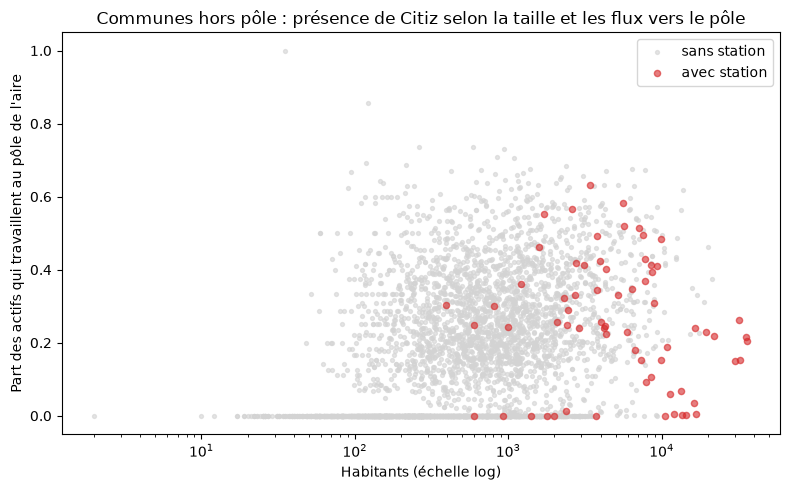

,nom,LIBAAV2020,territoire,population,part_vers_pole_aire,part_sans_voiture,nb_arrets,nb_points_charge
3290,Givors,Lyon,1 grande aire · couronne,21379,0.373908,0.202404,27.0,51.0
2864,Cournon-d'Auvergne,Clermont-Ferrand,1 grande aire · couronne,19951,0.463425,0.100313,79.0,38.0
3036,Riom,Clermont-Ferrand,1 grande aire · couronne,18820,0.311027,0.152796,142.0,73.0
2255,Firminy,Saint-Étienne,1 grande aire · couronne,17060,0.330125,0.254750,93.0,40.0
2429,Saint-Just-Saint-Rambert,Saint-Étienne,1 grande aire · couronne,15764,0.349016,0.064012,59.0,13.0
3456,Mions,Lyon,1 grande aire · couronne,13843,0.619547,0.070573,10.0,17.0
3450,Genas,Lyon,1 grande aire · couronne,13421,0.563416,0.056122,2.0,26.0
3230,Brignais,Lyon,1 grande aire · couronne,12503,0.486246,0.103651,1.0,22.0
3020,Pont-du-Château,Clermont-Ferrand,1 grande aire · couronne,12412,0.428038,0.078276,73.0,18.0
2208,Le Chambon-Feugerolles,Saint-Étienne,1 grande aire · couronne,12314,0.435431,0.210252,75.0,2.0


213 communes de ce profil sans station


In [32]:
zone = com[com["position"].isin(["couronne", "pôle secondaire", "hors aire"])].copy()
zone["taille_commune"] = pd.cut(zone["population"], [0, 2_000, 5_000, 10_000, np.inf],
                                labels=["< 2 000", "2 à 5 000", "5 à 10 000", "≥ 10 000"])
zone["flux_vers_pole"] = pd.cut(zone["part_vers_pole_aire"], [-0.01, 0.2, 0.4, 1],
                                labels=["< 20 %", "20 à 40 %", "> 40 %"])
display(zone.pivot_table(index="taille_commune", columns="flux_vers_pole", values="desservie",
                         aggfunc=["mean", "size"], observed=False).round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for d, coul in [(False, "lightgray"), (True, "tab:red")]:
    z = zone[zone["desservie"] == d]
    ax.scatter(z["population"], z["part_vers_pole_aire"], s=8 if not d else 20, c=coul,
               label="avec station" if d else "sans station", alpha=0.6)
ax.set_xscale("log"); ax.set_xlabel("Habitants (échelle log)"); ax.set_ylabel("Part des actifs qui travaillent au pôle de l'aire")
ax.set_title("Communes hors pôle : présence de Citiz selon la taille et les flux vers le pôle")
ax.legend(); plt.tight_layout(); plt.show()

# Communes qui ressemblent aux communes desservies mais n'ont pas de station : premières pistes, pas encore un classement
pistes = zone[(~zone["desservie"]) & (zone["population"] >= 2_000) & (zone["part_vers_pole_aire"] >= 0.3) & (zone["nb_arrets"] > 0)]
display(pistes.sort_values("population", ascending=False)[["nom", "LIBAAV2020", "territoire", "population", "part_vers_pole_aire",
                                                             "part_sans_voiture", "nb_arrets", "nb_points_charge"]].head(25))
print(len(pistes), "communes de ce profil sans station")

## Ce qu'on retiendra (à compléter après exécution)

- Où sont les stations, par type de territoire (cellule 4 et 11).
- Les communes de la couronne des grandes villes avec station ont-elles plus d'actifs qui vont travailler au pôle ? (cellule 12)
- Les petites communes sans station : combien ressemblent aux communes desservies ? (liste de la cellule 12)
- Ce que l'EDA ne dit pas : l'usage réel des stations. Prochaine étape : relier ces variables à l'occupation observée dans le relevé de disponibilité.

In [33]:
d = pd.read_csv(DONNEES / "station_status_2026-10-19.csv", usecols=["ts"])
print(d["ts"].nunique(), "relevés ;", d["ts"].min(), "->", d["ts"].max())

3 relevés ; 2026-10-19T14:54:33+00:00 -> 2026-10-19T15:00:05+00:00
